In [1]:
import torch

Let's create some dummy data

In [2]:
x = torch.arange(10, 100, 10)
print(f"Length of x: {len(x)}")
x

Length of x: 9


tensor([10, 20, 30, 40, 50, 60, 70, 80, 90])

Let this be a timeseries with 9 observations.
Now, often, it is the case that you dont need all the observations to make a prediction.

Imagine you are predicting weather: is the weather from 4 months ago relevant for the prediction of tomorrow? Probably not that much.
So, typically, we will have to determine a relevant window of time. 

This will vary from case to case. In this case, let the optimal window be 3.

In [3]:
idx = torch.tensor([0, 1, 2])
x[idx]

tensor([10, 20, 30])

This is our first training example. But, because time flows, we could "simulate" this by extracting an additional training example, also of lenght 3:

In [4]:
idx = torch.tensor([1, 2, 3])
x[idx]

tensor([20, 30, 40])

And we can continue this all the way to the end.

In [5]:
idx = torch.tensor([6, 7, 8])
x[idx]

tensor([70, 80, 90])

It would be easy to scale this process. So, we can provide multiple indeces at once:

In [6]:
idx = torch.tensor([[0, 1, 2], [1, 2, 3]])
x[idx]

tensor([[10, 20, 30],
        [20, 30, 40]])

This gives us two different training examples.
Now, what we would want, instead of typing out these indeces by hand, is to generate a complete set of indeces, for an array of a given lenght, with a given window.

In [7]:
n_time = 3
n_window = len(x) - n_time + 1
n_window

7

The minimum case is to extract one window of 3 from an array of length 3, which is the reason we need to add 1 to the formula.
If we increase the length of the array, for every single element extra on top of the length of the array, we can extract one more chunk.
This explains the len(x) - n_time part.

This formula can be used to calculate the maximum amount of slices we can extract from an array `x`: with a window of 3, we can squeeze out 7 training examples.

Now, the first index will look like this:

In [8]:
time = torch.arange(0, n_time).reshape(1, -1)
time

tensor([[0, 1, 2]])

And what we essentially need, to get the next slice, is to add +1 for every next slice.
Because we calculated that we are able to extract 7 slices, we need the numbers ranging from 0 to 6.

In [9]:
window = torch.arange(0, n_window).reshape(-1, 1)
window

tensor([[0],
        [1],
        [2],
        [3],
        [4],
        [5],
        [6]])

In [10]:
time.shape, window.shape

(torch.Size([1, 3]), torch.Size([7, 1]))

Using broadcasting, we can now simply add these two vectors. 

We are adding a (1,3) and a (7,1) matrix. This might seem weird, because you would expect to need two
(7,3) matrices, but Torch will expand the dimensions that don't match yet have a dimension of 1.

In [11]:
idx = time + window
idx

tensor([[0, 1, 2],
        [1, 2, 3],
        [2, 3, 4],
        [3, 4, 5],
        [4, 5, 6],
        [5, 6, 7],
        [6, 7, 8]])

Now, this is exactly what we need! This first index is still `[0, 1, 2]`, and the second index has the same, +1, so that is now `[1, 2, 3]` , etc.

Let's try this out on our timeseries:

In [12]:
x[idx]

tensor([[10, 20, 30],
        [20, 30, 40],
        [30, 40, 50],
        [40, 50, 60],
        [50, 60, 70],
        [60, 70, 80],
        [70, 80, 90]])

So, that worked! We started with a long timeseries of 9 steps. We ended up with seven examples to feed our model, all with a lenght of 3.

We can wrap this all into a function:

In [13]:
Tensor = torch.Tensor


def window(x: Tensor, n_time: int) -> Tensor:
    """
    Generates and index that can be used to window a timeseries.
    E.g. the single series [0, 1, 2, 3, 4, 5] can be windowed into 4 timeseries with
    length 3 like this:

    [0, 1, 2]
    [1, 2, 3]
    [2, 3, 4]
    [3, 4, 5]

    We now can feed 4 different timeseries into the model, instead of 1, all
    with the same length.
    """
    n_window = len(x) - n_time + 1
    time = torch.arange(0, n_time).reshape(1, -1)
    window = torch.arange(0, n_window).reshape(-1, 1)
    idx = time + window
    return idx

Now we can easily change the window size:

In [14]:
idx = window(x, 5)
x[idx]

tensor([[10, 20, 30, 40, 50],
        [20, 30, 40, 50, 60],
        [30, 40, 50, 60, 70],
        [40, 50, 60, 70, 80],
        [50, 60, 70, 80, 90]])

In [15]:
idx = window(x, 6)
x[idx]

tensor([[10, 20, 30, 40, 50, 60],
        [20, 30, 40, 50, 60, 70],
        [30, 40, 50, 60, 70, 80],
        [40, 50, 60, 70, 80, 90]])

Will this scale to more dimensions?
Let's imagine we have 5 timesteps, every timestep 3 features being observed. 
We can organize that into a `(5x3)` matrix instead of the one-dimensional raw data we started this notebook with.

In [16]:
x = torch.randint(0, 10, (5, 3))
x

tensor([[0, 7, 7],
        [5, 2, 4],
        [1, 8, 1],
        [4, 8, 1],
        [2, 4, 9]])

Now lets window it in chunks of 4 timesteps:

In [17]:
idx = window(x, 4)
x[idx]

tensor([[[0, 7, 7],
         [5, 2, 4],
         [1, 8, 1],
         [4, 8, 1]],

        [[5, 2, 4],
         [1, 8, 1],
         [4, 8, 1],
         [2, 4, 9]]])

We can use the windowed index to generate three training examples, every training examples covering four timesteps.

We can also apply this to batched. Let us have a batch (B) of 32 examples, every example having 6 timesteps (T) and 2 features (F). This is organized in a `(B, T, F)` matrix.

We can now apply the window on the 0th example, and squueze out an additional 3 training examples

In [18]:
batch = torch.randint(0, 10, (32, 6, 2))
x = batch[0]
idx = window(x, 4)
x_windowed = x[idx]

In [19]:
x.shape, x_windowed.shape

(torch.Size([6, 2]), torch.Size([3, 4, 2]))

# Part 2: the same operation, on a real series

Everything above was nine numbers and a broadcast. Now we do it to data somebody
actually recorded, and find out that the hard part of windowing is not the index
arithmetic — it is deciding *what you are allowed to window over*.

The series is **daily sunspot counts** — you have already met it, in MADS-DAV
(`03.2-statistics-of-time.ipynb`). One column, no covariates: how many sunspots were
visible on the Sun's disc, counted every day since 1818. Predicting solar activity is
somebody's actual job — it drives radio-communication blackout risk, satellite drag,
and geomagnetic-storm warnings for power grids. It is also a genuinely public, very
old dataset (CC-BY-4.0, Royal Observatory of Belgium), which matters later in this
lesson when a foundation model gets asked whether it has seen a series before.

In [20]:
import matplotlib.pyplot as plt
import torch

from ett import window_index
from sunspot_daily import load_sunspot_daily

sun = load_sunspot_daily()
sun

Sunspot(62617 daily steps, 1848-12-23 .. 2020-05-31, split 55313/3652/3652)

## The row is the series

Look at what one row of this dataset *is* before trusting it. Timeseries datasets on
the hub overwhelmingly follow the **GluonTS convention**, and it catches people out:

| field | what it holds |
|---|---|
| `start` | timestamp of the **first** observation |
| `target` | the whole series, as one list |
| `feat_dynamic_real` | covariates, `(n_covariates, T)` — one value per timestep |
| `feat_static_cat` | properties of the series itself (which sensor, which store) |
| `item_id` | the series' name |

So **one row is an entire series, not a timestep.** A dataset with 66 rows has 66
series, not 66 observations. Once you have read one of these you can read the whole
Monash catalog, which is most of the public timeseries data there is.

62617 daily steps of sunspot number, 1848-12-23 to 2020-05-31


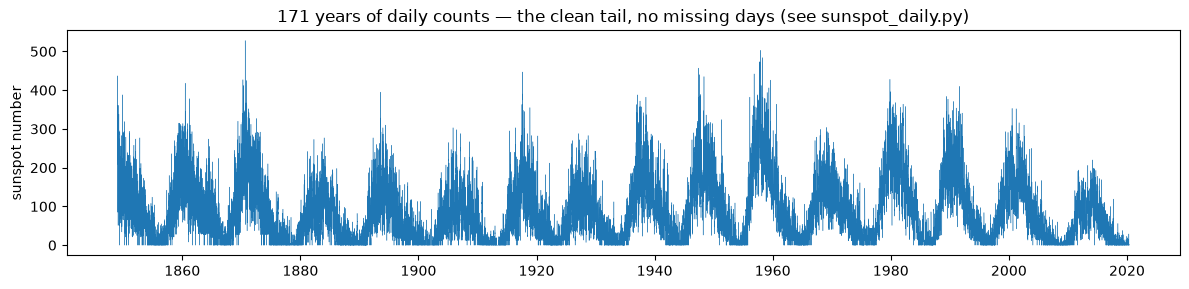

In [21]:
print(f"{len(sun)} daily steps of sunspot number, "
      f"{sun.timestamps[0]:%Y-%m-%d} to {sun.timestamps[-1]:%Y-%m-%d}")

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(sun.timestamps, sun.values, lw=0.3)
ax.set_ylabel("sunspot number")
ax.set_title("171 years of daily counts — the clean tail, no missing days (see sunspot_daily.py)")
plt.tight_layout()

## The split that is not a split

`Monash-University/monash_tsf`'s `sunspot` config ships `train`, `validation` and
`test` splits, same as every other Monash/GluonTS-convention dataset on the hub. Take
them at face value and you have already lost — same trap `ett.py` names, on a
completely different series, because it is a convention, not a coincidence.

In [22]:
from datasets import load_dataset

raw = {
    s: load_dataset("Monash-University/monash_tsf", revision="refs/convert/parquet",
                    data_files={s: f"sunspot/{s}/0000.parquet"})[s]
    for s in ("train", "validation", "test")
}
for name, ds in raw.items():
    lengths = [len(r) for r in ds["target"]]
    print(f"{name:11s} {ds.num_rows:3d} row, target length {min(lengths)} .. {max(lengths)}")

train         1 row, target length 73864 .. 73864
validation    1 row, target length 73894 .. 73894
test          1 row, target length 73924 .. 73924


In [23]:
train_series = torch.tensor(raw["train"][0]["target"])
test_series = torch.tensor(raw["test"][-1]["target"])

# equal_nan=True because the early 19th-century record has real gaps (sunspot_daily.py) --
# without it torch.equal reports False even where every recorded value matches, since
# NaN != NaN. That is a fact about floating point, not about whether the prefix holds.
prefix = test_series[: len(train_series)]
overlap = torch.allclose(prefix, train_series, equal_nan=True)
print(f"is the training series literally the first {len(train_series)} steps of the test row? {overlap}")

is the training series literally the first 73864 steps of the test row? True


`True`. The splits are **prefixes of one another**, not disjoint sets: here each split
is a single row, and `test` simply continues 30 days past where `validation` stops,
which continues 30 days past where `train` stops. Hand these three straight to a
`DataLoader` as train/test and every "test" step already sat inside what you called
training data.

Nothing would crash. Your test score would just be wonderful.

The defence is not cleverness, it is looking — and once you have looked, the fix is
also not "use Monash's splits more cleverly." Thirty days either way is nowhere near
enough to validate or test a model on. `sunspot_daily.py` does what `ett.py` does:
take the single longest row, and cut it in *calendar* time yourself. Here that also
means dropping the gappy pre-1849 stretch — a missing day breaks a window outright,
where it barely moves a yearly mean (which is why `03_decomposition_and_nbeats` §3.7
can use the full 1818-2020 record and this notebook cannot).

In [24]:
for name, s in sun.splits.items():
    a, b = sun.timestamps[s.start], sun.timestamps[s.stop - 1]
    print(f"{name:5s} [{s.start:6d}:{s.stop:6d}]  {a:%Y-%m-%d} .. {b:%Y-%m-%d}  ({s.stop - s.start} days)")

train [     0: 55313]  1848-12-23 .. 2000-06-01  (55313 days)
val   [ 55313: 58965]  2000-06-02 .. 2010-06-01  (3652 days)
test  [ 58965: 62617]  2010-06-02 .. 2020-05-31  (3652 days)


## Split first, *then* window

Order matters, and it is not obvious which way round. Window first and then split,
and the windows straddling the boundary contain training steps in their history and
test steps in their target. That is a handful of contaminated rows out of thousands —
too few to notice in a score, which is precisely what makes it dangerous.

Split first and those windows never exist. You lose `W + H - 1` windows at each
boundary. Pay it.

In [25]:
W, H = 81, 27  # three rotations of history, one ahead -- see 02_basemodels for why 27


def to_windows(split: str, stride: int = 1):
    # (x, y) for one split: x is (N, W) of history, y the (N, H) it has to predict
    values = sun.values[sun.splits[split]]
    idx = window_index(len(values), W + H, stride)
    windowed = values[idx]
    return windowed[:, :W], windowed[:, W:]


for split in sun.splits:
    x, y = to_windows(split)
    print(f"{split:5s} x {tuple(x.shape)}  y {tuple(y.shape)}")

train x (55206, 81)  y (55206, 27)
val   x (3545, 81)  y (3545, 27)
test  x (3545, 81)  y (3545, 27)


## Normalise on the training statistics, and only those

The old question from this lesson was *what would go wrong if you normalised by the
maximum of the test set?* Here is the answer with a number attached: solar activity in
the 2000s test window is not at the same level as the 1850-1999 training span — the
Sun's ~11-year cycle means "the max so far" keeps changing, which is exactly why you
fit the scaler once, on train, and never again.

In [26]:
tr = sun.values[sun.splits["train"]]
te = sun.values[sun.splits["test"]]
print(f"train  mean {tr.mean():6.2f}  std {tr.std():5.2f}  max {tr.max():6.2f}")
print(f"test   mean {te.mean():6.2f}  std {te.std():5.2f}  max {te.max():6.2f}")

mu, sigma = tr.mean(), tr.std()  # fitted on train, applied everywhere
print(f"\nscaling with train statistics: (x - {mu:.2f}) / {sigma:.2f}")
print(f"test data lands at mean {((te - mu) / sigma).mean():.2f}, std {((te - mu) / sigma).std():.2f}")

train  mean  87.24  std 78.99  max 528.00
test   mean  53.28  std 47.65  max 220.00

scaling with train statistics: (x - 87.24) / 78.99
test data lands at mean -0.43, std 0.60


The scaled test set is *not* centred on zero, and it should not be — that offset is
real information about the future that your scaler is not allowed to know. A scaler
fitted on everything would have hidden it, and hidden it in a way that flatters every
model you go on to train.

## The overlap you are allowed to keep

One more thing about windowing that only shows up on real data: consecutive windows
are nearly the same window. At `W=81`, neighbours share 80 of 81 steps.

In [27]:
x, y = to_windows("train")
print(f"stride 1:  {len(x)} windows, neighbours share {W - 1}/{W} steps")
for stride in (3, 27):
    xs, _ = to_windows("train", stride)
    print(f"stride {stride:2d}: {len(xs):6d} windows  ({len(x) / len(xs):.0f}x smaller epoch)")

stride 1:  55206 windows, neighbours share 80/81 steps
stride  3:  18402 windows  (3x smaller epoch)
stride 27:   2045 windows  (27x smaller epoch)


That is not leakage — every window still sits entirely inside the training span — but
it does mean an epoch over stride-1 windows shows the model nearly the same three
months tens of thousands of times over. Striding is the cheapest speed lever this
lesson has, and `02_basemodels` uses it deliberately rather than by accident.

## Where this leaves us on the ladder

`tensor-ladder.md` asks what each axis *means*, not just how long it is. We started
with one series of 62,617 numbers and ended with:

```
x : (N, W)      N windows, each W steps of history      -> (B, T) once batched
y : (N, H)      the H steps each window has to predict
```

and the moment a model wants more than the target's own past — the hour or day of the
year, features you design yourself — that `(B, T)` grows a feature axis and becomes
`(B, T, F)`. Rung 3. Everything from here on lives on that shape.